# Validate Jaeger quality for GAT-GRU

Notebook này đánh giá chất lượng dữ liệu Jaeger/Prometheus trước khi dùng các feature từ Jaeger để train GAT-GRU.

Mục tiêu:
- check coverage Jaeger so với Locust
- kiểm tra service_metrics và edge_metrics theo run
- đánh giá độ tin cậy của latency p50/p95
- kiểm tra tính nhất quán topology giữa các run


In [18]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'dataset' / 'raw').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Could not locate repository root containing dataset/raw')
RESULTS = ROOT / 'dataset' / 'raw'
SCENARIOS = ['nhpp', 'mmpp', 'pareto', 'onoff']
SERVICES = ['adservice', 'cartservice', 'checkoutservice', 'currencyservice', 'emailservice', 'frontend', 'paymentservice', 'productcatalogservice', 'recommendationservice', 'redis-cart', 'shippingservice']
RESULTS

WindowsPath('F:/0. UIT/KLTN/thesis-gnn-rl-autoscaling/math-load-testing/results')

## 1. Cấu hình và load dữ liệu

- Quét tự động `results/{scenario}/run_*`
- Không hardcode từng run
- Nếu file thiếu thì báo warning nhưng không crash


In [19]:
def read_csv_if_exists(path):
    if not path.exists():
        return None
    try:
        return pd.read_csv(path)
    except Exception as exc:
        print(f'⚠️ Không đọc được {path.name}: {exc}')
        return None

def read_json_if_exists(path):
    if not path.exists():
        return {}
    try:
        with open(path, 'r', encoding='utf-8') as f:
            return json.load(f)
    except Exception as exc:
        print(f'⚠️ Không đọc được {path.name}: {exc}')
        return {}

def find_runs():
    runs = []
    for scenario in SCENARIOS:
        scenario_dir = RESULTS / scenario
        if not scenario_dir.exists():
            print(f'⚠️ Missing scenario folder: {scenario_dir}')
            continue
        for run_dir in sorted(scenario_dir.glob('run_*')):
            if run_dir.is_dir():
                runs.append(run_dir)
    return runs

RUNS = find_runs()
print(f'Total runs found: {len(RUNS)}')
RUNS[:2]

Total runs found: 32


[WindowsPath('F:/0. UIT/KLTN/thesis-gnn-rl-autoscaling/math-load-testing/results/nhpp/run_01'),
 WindowsPath('F:/0. UIT/KLTN/thesis-gnn-rl-autoscaling/math-load-testing/results/nhpp/run_02')]

In [20]:
def estimate_locust_total_requests(run_dir):
    for name in ['locust_stats.csv', 'locust_stats_history.csv', 'locust_history.csv']:
        path = run_dir / name
        df = read_csv_if_exists(path)
        if df is None or df.empty:
            continue
        if 'Request Count' in df.columns:
            agg = df[df['Name'].astype(str).str.contains('Aggregated', case=False, na=False)]
            if not agg.empty:
                return float(agg['Request Count'].iloc[-1])
            return float(df['Request Count'].sum())
        if 'Total Request Count' in df.columns:
            agg = df[df.astype(str).apply(lambda s: s.str.contains('Aggregated', case=False, na=False)).any(axis=1)]
            if not agg.empty:
                return float(agg['Total Request Count'].iloc[-1])
            return float(df['Total Request Count'].iloc[-1])
    return np.nan

def read_run_summary(run_dir):
    scenario = run_dir.parent.name
    run_id = run_dir.name
    meta = read_json_if_exists(run_dir / 'meta.json')
    driver = read_json_if_exists(run_dir / 'driver_report.json')
    collect = read_json_if_exists(run_dir / 'collect_report.json')
    service_df = read_csv_if_exists(run_dir / 'service_metrics.csv')
    node_df = read_csv_if_exists(run_dir / 'node_metrics.csv')
    locust_total = estimate_locust_total_requests(run_dir)

    frontend_requests = 0.0
    if service_df is not None and not service_df.empty:
        frontend = service_df[service_df['service'].astype(str).str.lower() == 'frontend']
        if 'request_count' in frontend.columns:
            frontend_requests = float(frontend['request_count'].sum())

    jaeger_coverage = np.nan
    if pd.notna(locust_total) and locust_total > 0:
        jaeger_coverage = frontend_requests / locust_total

    prom_cov = np.nan
    if node_df is not None and not node_df.empty:
        ts = pd.to_numeric(node_df['timestamp'], errors='coerce').dropna()
        if not ts.empty:
            step = int(meta.get('step_sec', 10))
            start = int(ts.min())
            end = int(ts.max())
            expected = max(1, ((end - start) // step) + 1)
            prom_cov = len(ts.unique()) / expected

    return {
        'scenario': scenario,
        'run_id': run_id,
        'locust_total_requests': locust_total,
        'jaeger_frontend_requests': frontend_requests,
        'jaeger_coverage': jaeger_coverage,
        'prometheus_coverage': prom_cov,
        'jaeger_truncated_windows': int(collect.get('jaeger_truncated_windows', 0)) if isinstance(collect, dict) else 0,
        'dropped_ratio': float(driver.get('dropped_ratio', np.nan)) if isinstance(driver, dict) else np.nan,
    }

run_summary = pd.DataFrame([read_run_summary(r) for r in RUNS])
run_summary = run_summary.sort_values(['scenario', 'run_id']).reset_index(drop=True)
run_summary.head(12)

,scenario,run_id,locust_total_requests,jaeger_frontend_requests,jaeger_coverage,prometheus_coverage,jaeger_truncated_windows,dropped_ratio
0,mmpp,run_01,48534.0,5525.0,0.113838,1.0,0,0.0
1,mmpp,run_02,63483.0,7256.0,0.114298,1.0,0,0.0
2,mmpp,run_03,46215.0,5252.0,0.113643,1.0,0,0.0
3,mmpp,run_04,53343.0,6019.0,0.112836,1.0,0,0.0
4,mmpp,run_05,62037.0,7082.0,0.114158,1.0,0,0.0
5,mmpp,run_06,73571.0,8411.0,0.114325,1.0,0,0.0
6,mmpp,run_07,39699.0,4521.0,0.113882,1.0,0,0.0
7,mmpp,run_08,50789.0,5880.0,0.115773,1.0,0,0.0
8,nhpp,run_01,75432.0,8570.0,0.113612,1.0,0,0.0
9,nhpp,run_02,75230.0,8603.0,0.114356,1.0,0,0.0


## 2. Tính `jaeger_coverage` toàn run

Công thức ưu tiên: `jaeger_coverage = total frontend request_count / total requests thực tế từ Locust`

Nếu file Locust có dòng `Aggregated` thì dùng tổng trên dòng đó; nếu có file history thì lấy cumulative total theo thời gian.


scenario run_id  locust_total_requests  jaeger_frontend_requests  jaeger_coverage  prometheus_coverage  jaeger_truncated_windows  dropped_ratio
    mmpp run_01                48534.0                    5525.0         0.113838                  1.0                         0            0.0
    mmpp run_02                63483.0                    7256.0         0.114298                  1.0                         0            0.0
    mmpp run_03                46215.0                    5252.0         0.113643                  1.0                         0            0.0
    mmpp run_04                53343.0                    6019.0         0.112836                  1.0                         0            0.0
    mmpp run_05                62037.0                    7082.0         0.114158                  1.0                         0            0.0
    mmpp run_06                73571.0                    8411.0         0.114325                  1.0                         0        

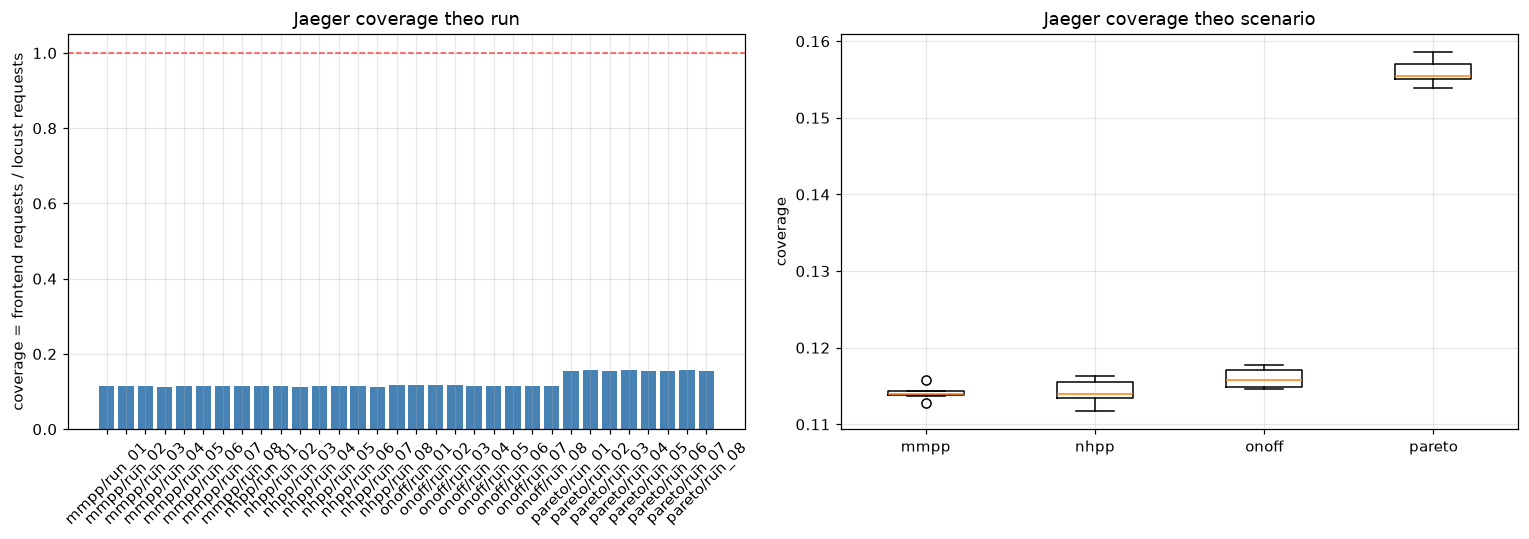

In [21]:
print(run_summary[['scenario', 'run_id', 'locust_total_requests', 'jaeger_frontend_requests', 'jaeger_coverage', 'prometheus_coverage', 'jaeger_truncated_windows', 'dropped_ratio']].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bar_data = run_summary.sort_values(['scenario', 'run_id']).copy()
bar_data['label'] = bar_data['scenario'] + '/' + bar_data['run_id']
axes[0].bar(bar_data['label'], bar_data['jaeger_coverage'], color='steelblue')
axes[0].axhline(1.0, color='red', linestyle='--', lw=1, alpha=0.7)
axes[0].set_title('Jaeger coverage theo run')
axes[0].set_ylabel('coverage = frontend requests / locust requests')
axes[0].tick_params(axis='x', rotation=45)

scenario_names = sorted(bar_data['scenario'].unique())
scenario_groups = [bar_data.loc[bar_data['scenario'] == scenario, 'jaeger_coverage'].dropna().to_numpy() for scenario in scenario_names]
axes[1].boxplot(scenario_groups)
axes[1].set_xticks(range(1, len(scenario_names) + 1))
axes[1].set_xticklabels(scenario_names)
axes[1].set_title('Jaeger coverage theo scenario')
axes[1].set_ylabel('coverage')
plt.tight_layout()
plt.show()

## 3. Jaeger quality: alignment, reliability and verdict

Canonical quality analysis. Locust cumulative history and Jaeger service counts are bucketed onto the same run grid using `meta.json`. Sparse service or edge windows are not automatically classified as trace loss.
Reports are written to `dataset/processed/gatgru/jaeger_quality/`.


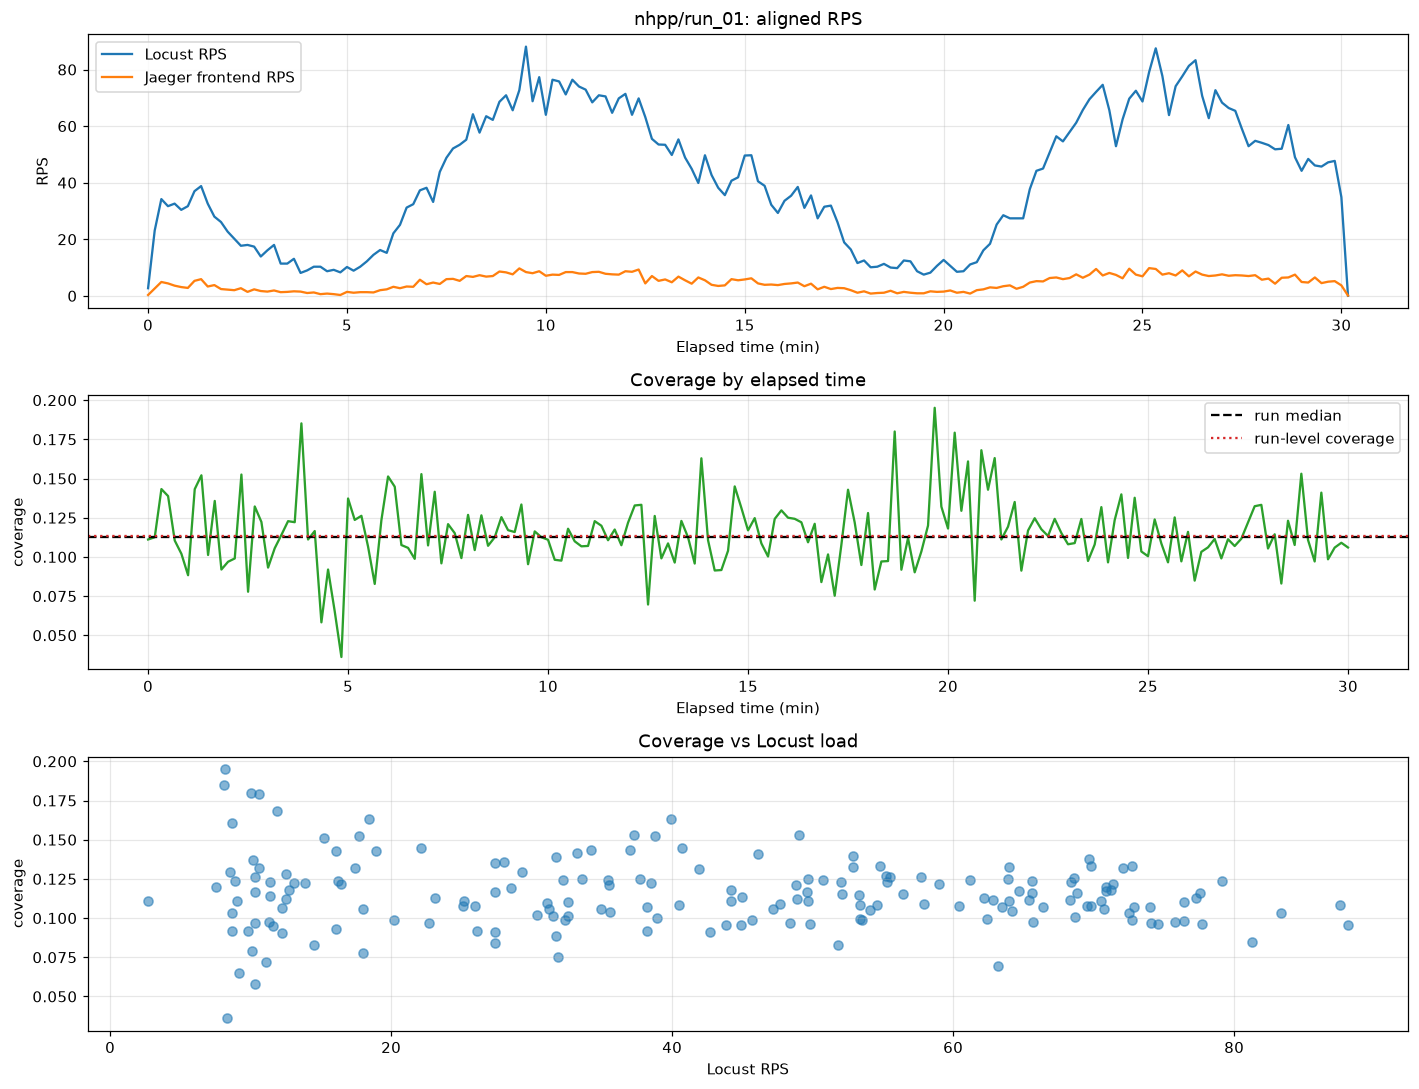

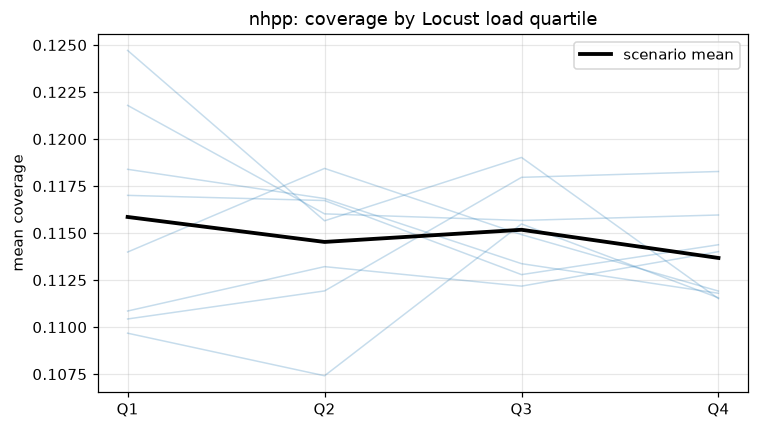

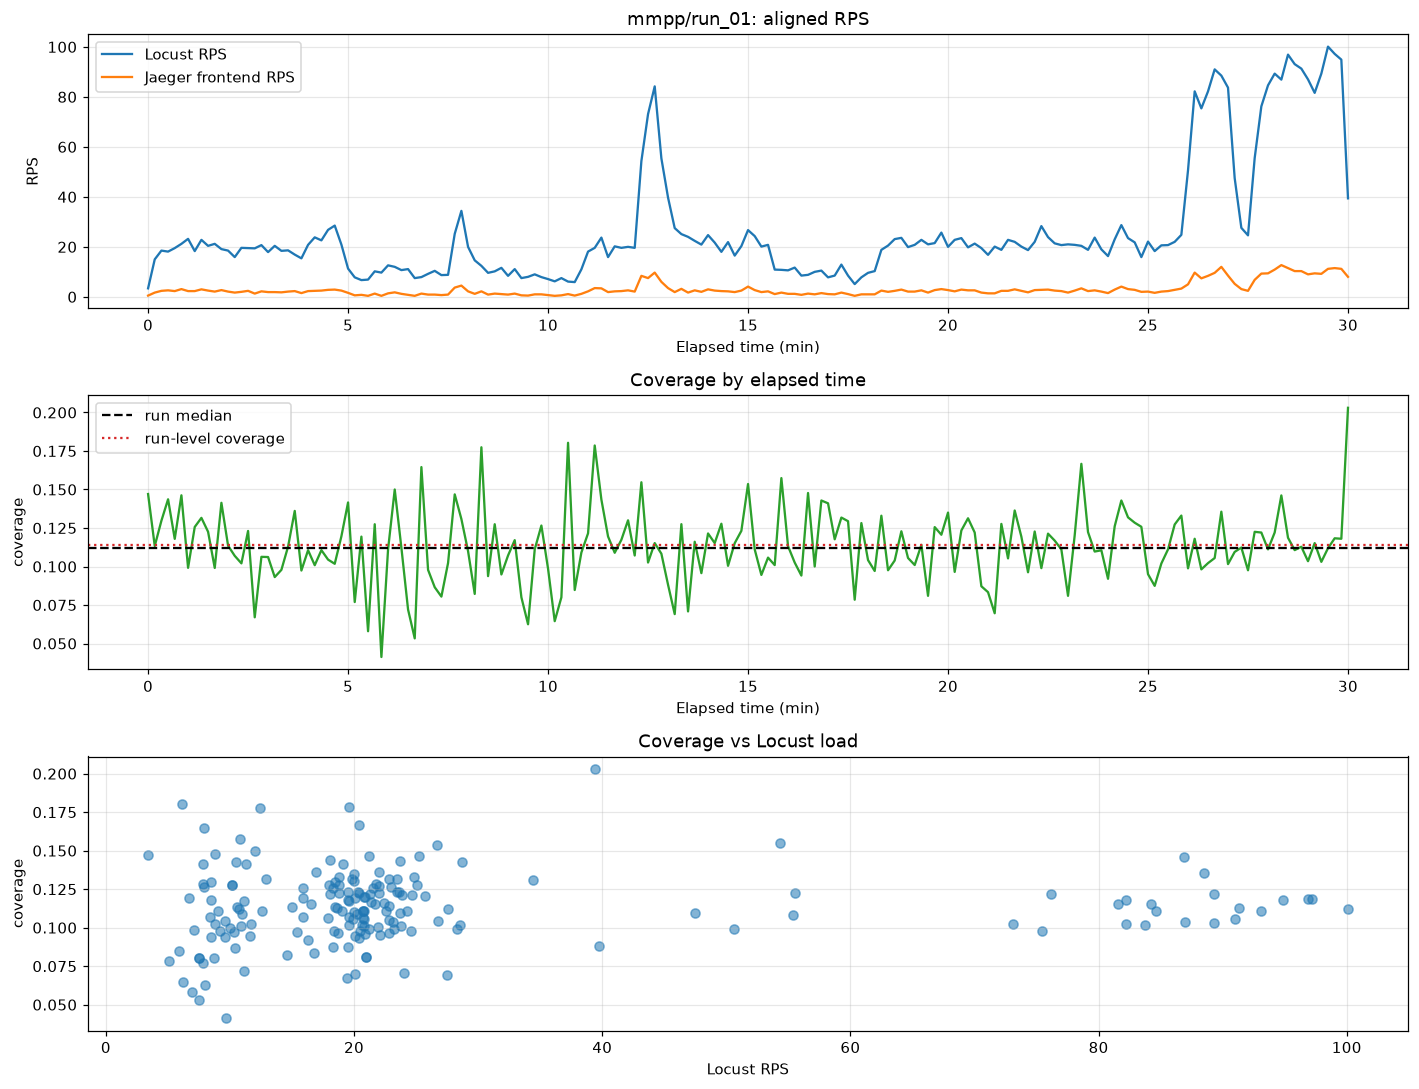

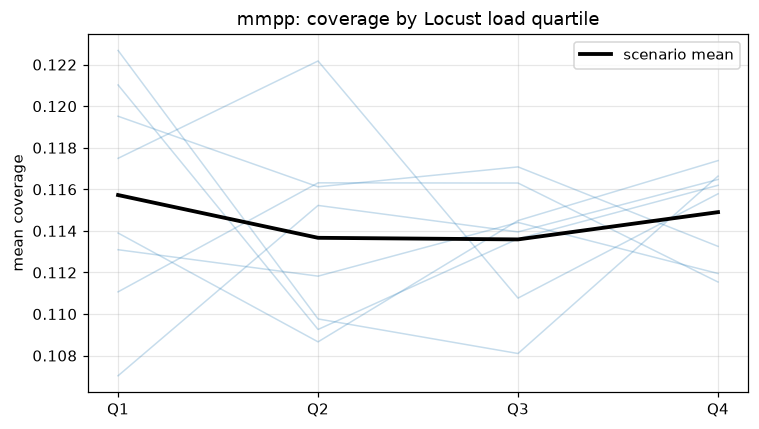

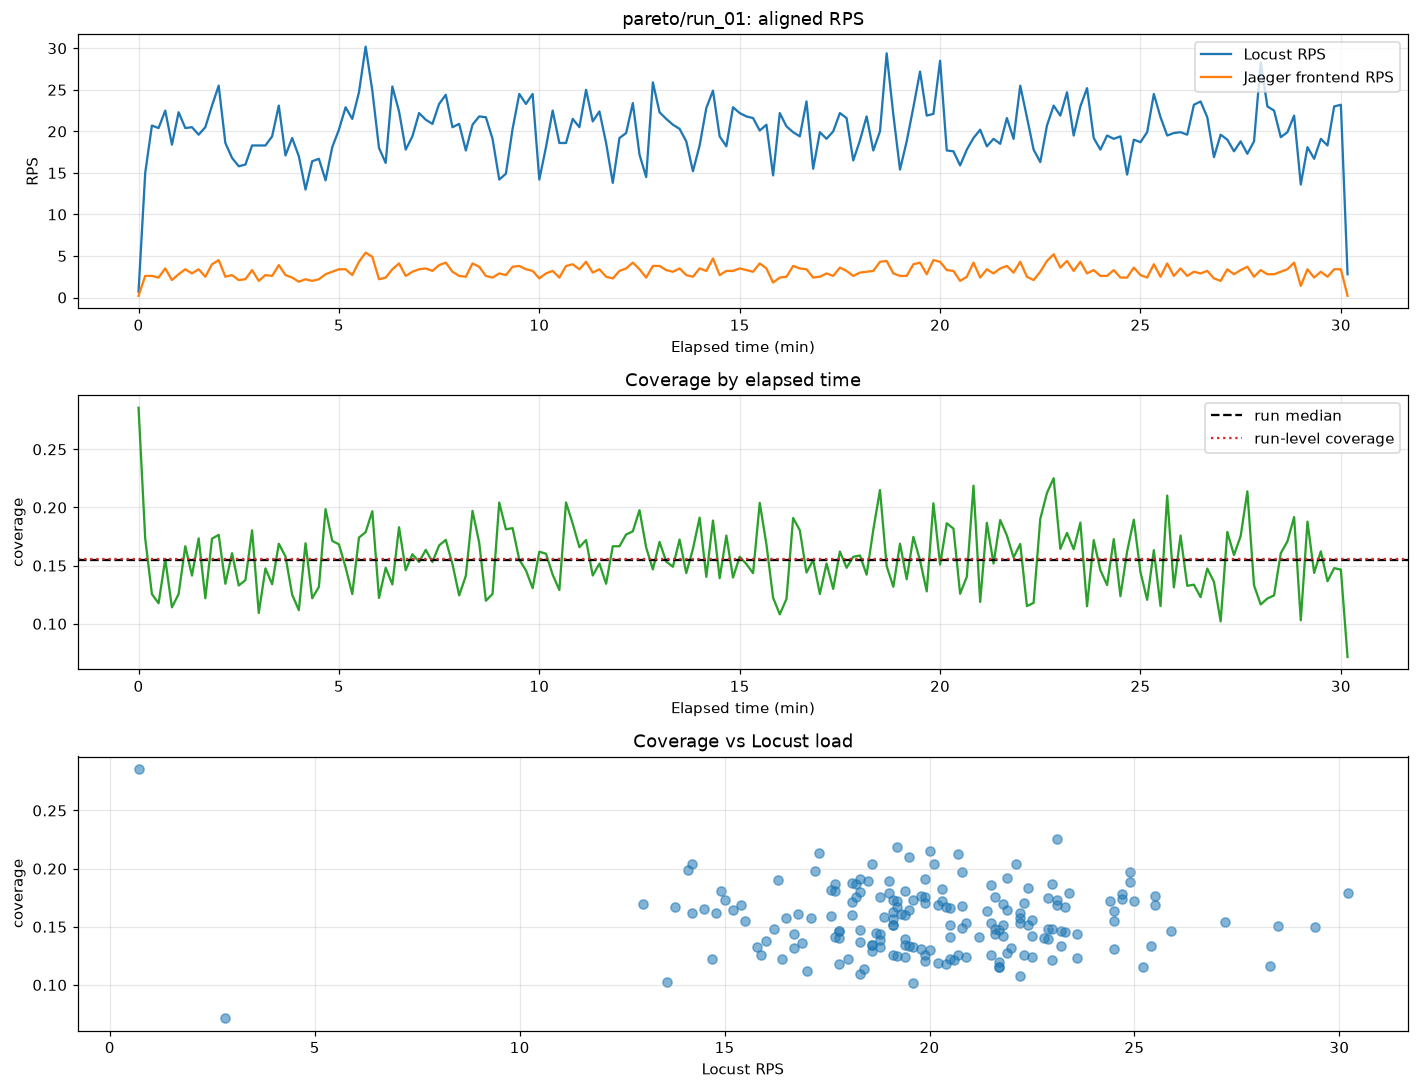

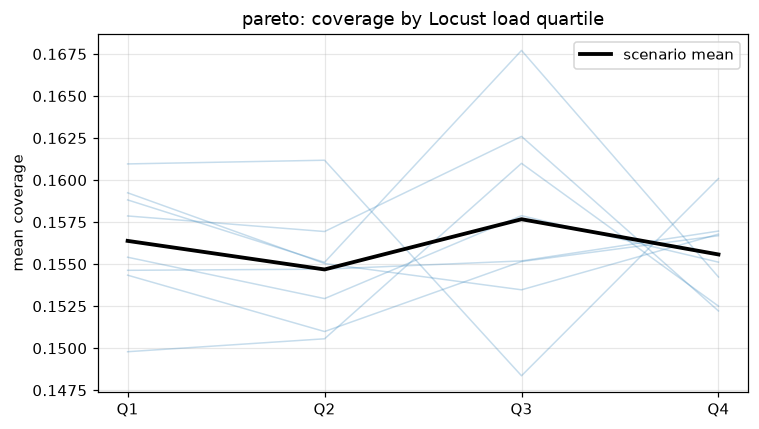

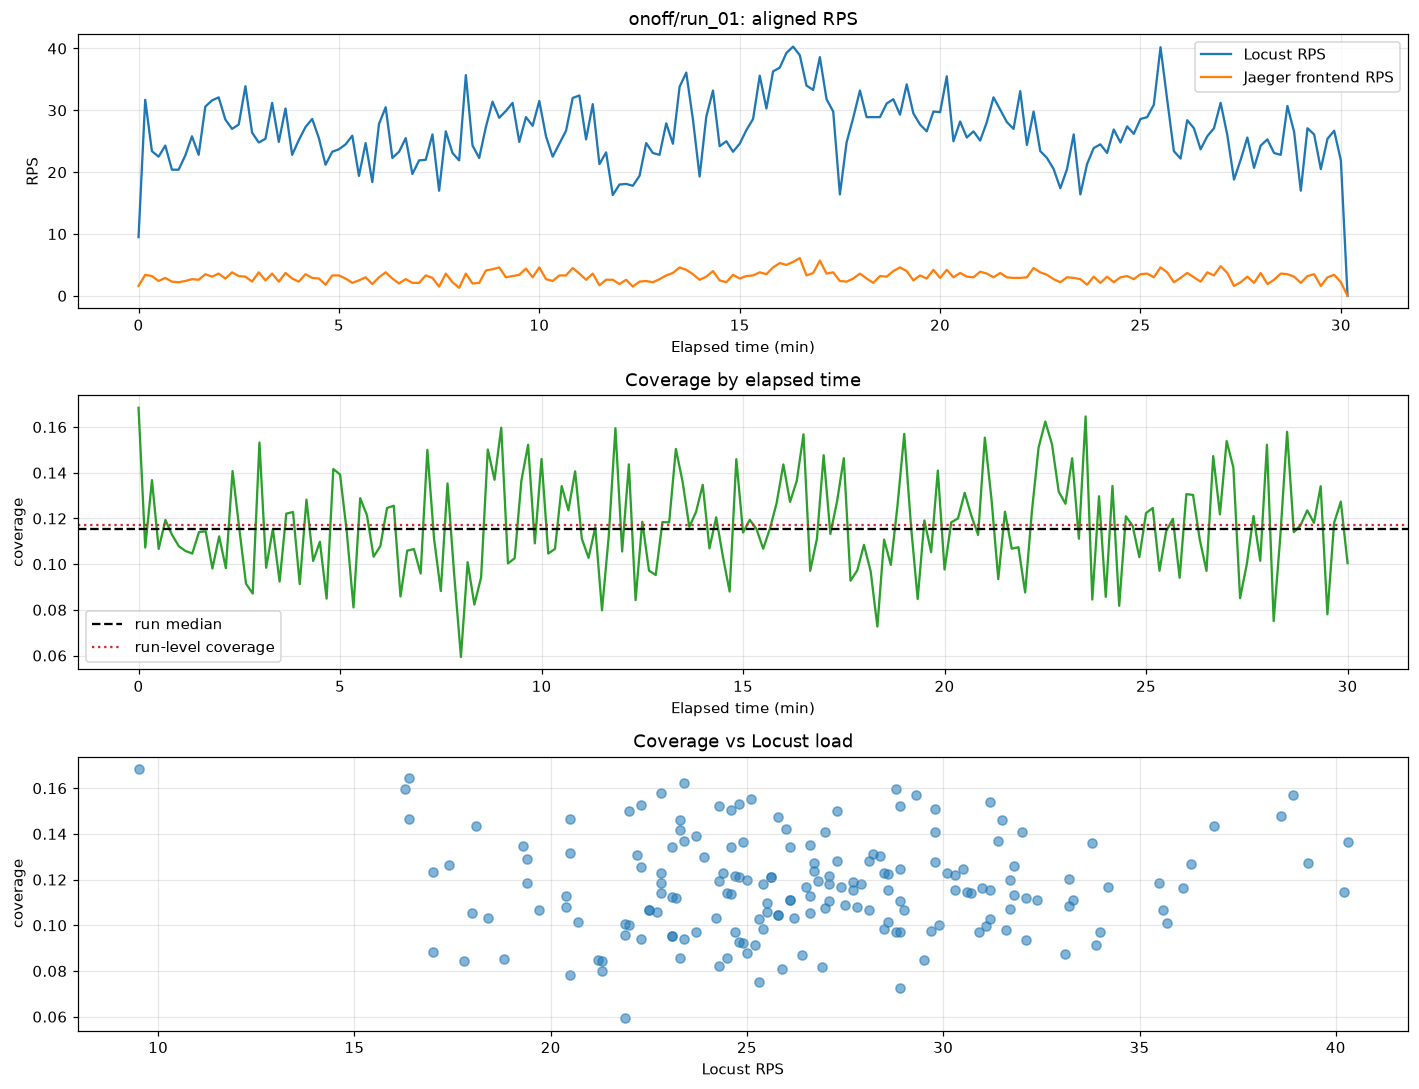

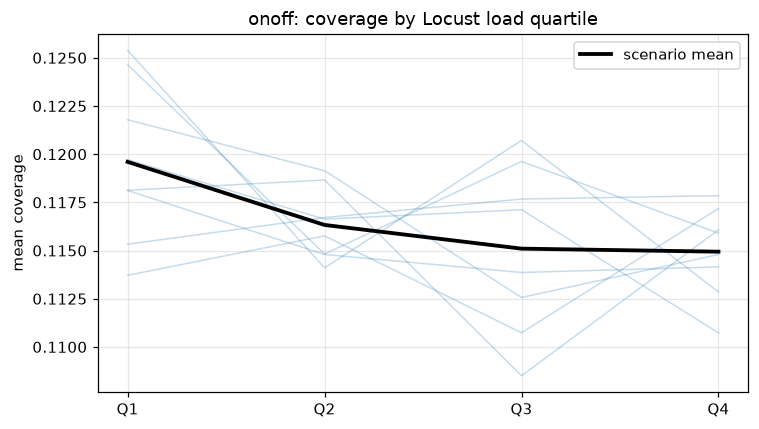

nhpp topology Jaccard mean/min/max: (np.float64(1.0), np.float64(1.0), np.float64(1.0))
mmpp topology Jaccard mean/min/max: (np.float64(1.0), np.float64(1.0), np.float64(1.0))
pareto topology Jaccard mean/min/max: (np.float64(1.0), np.float64(1.0), np.float64(1.0))
onoff topology Jaccard mean/min/max: (np.float64(1.0), np.float64(1.0), np.float64(1.0))

=== OVERALL VERDICT ===
Run-level Jaeger coverage by scenario:
scenario  mean_jaeger_coverage  median_jaeger_coverage
    mmpp              0.114094                0.114020
    nhpp              0.114284                0.114019
   onoff              0.115992                0.115765
  pareto              0.155966                0.155520
Coverage stability by load quartile:
scenario
mmpp      0.987673
nhpp      0.979674
onoff     0.954511
pareto    0.996353
Coverage > 1 after alignment, median by scenario:
scenario
mmpp      0.0
nhpp      0.0
onoff     0.0
pareto    0.0
Static topology consistency:
scenario
mmpp      1.0
nhpp      1.0
ono

In [22]:
quality_dir = ROOT / 'dataset' / 'processed' / 'gatgru' / 'jaeger_quality'
quality_dir.mkdir(parents=True, exist_ok=True)


def run_grid(run_dir):
    meta = read_json_if_exists(run_dir / 'meta.json')
    step = int(meta.get('step_sec') or 10)
    start = int(meta.get('start', 0))
    end = int(meta.get('end', 0))
    aligned_start = start - start % step
    return meta, step, aligned_start, end, np.arange(aligned_start, end, step, dtype=np.int64)


def locust_history_frame(run_dir):
    path = next((run_dir / n for n in ('locust_stats_history.csv', 'locust_history.csv')
                 if (run_dir / n).exists()), None)
    cols = ['timestamp', 'locust_count_raw_interval', 'counter_reset']
    if path is None:
        print(f'⚠️ Missing Locust history: {run_dir}')
        return pd.DataFrame(columns=cols)
    df = read_csv_if_exists(path)
    if df is None or df.empty:
        return pd.DataFrame(columns=cols)
    ts = next((c for c in ('Timestamp', 'timestamp') if c in df), None)
    total = next((c for c in ('Total Request Count', 'total_request_count') if c in df), None)
    if ts is None or total is None:
        print(f'⚠️ Invalid Locust history columns: {path}')
        return pd.DataFrame(columns=cols)
    w = df.copy()
    w['_ts'] = pd.to_numeric(w[ts], errors='coerce')
    w['_total'] = pd.to_numeric(w[total], errors='coerce')
    w = w.dropna(subset=['_ts', '_total'])
    aggregated = pd.Series(False, index=w.index)
    if 'Name' in w:
        aggregated |= w['Name'].astype(str).str.strip().str.lower().eq('aggregated')
    if 'Type' in w:
        aggregated |= w['Type'].astype(str).str.strip().str.lower().eq('aggregated')
    if aggregated.any():
        w = w.loc[aggregated].groupby('_ts', as_index=False)['_total'].last()
    else:
        keys = ['_ts'] + [c for c in ('Type', 'Name') if c in w]
        w = w.drop_duplicates(keys, keep='last').groupby('_ts', as_index=False)['_total'].sum()
        print(f'⚠️ {path.name}: no Aggregated rows; combined per-endpoint cumulative totals.')
    w = w.sort_values('_ts').reset_index(drop=True)
    delta = w['_total'].diff()
    reset = delta < 0
    if reset.any():
        delta.loc[reset] = w.loc[reset, '_total']
        print(f'⚠️ {run_dir.name}: {int(reset.sum())} Locust counter reset(s); reset value used as interval count.')
    if len(delta):
        delta.iloc[0] = np.nan
    w['locust_count_raw_interval'] = delta
    w['counter_reset'] = reset
    return w.rename(columns={'_ts': 'timestamp'})[cols]


def resample_locust_to_grid(run_dir, meta=None):
    meta, step, start, end, grid = run_grid(run_dir)
    out = pd.DataFrame({'timestamp': grid})
    hist = locust_history_frame(run_dir)
    if hist.empty:
        out['locust_count'] = 0.0
        out['locust_counter_reset'] = False
        return out, step
    hist['bucket'] = start + np.floor((hist['timestamp'] - start) / step).astype('int64') * step
    hist = hist.loc[(hist['bucket'] >= start) & (hist['bucket'] < end)]
    grouped = hist.groupby('bucket').agg(
        locust_count=('locust_count_raw_interval', 'sum'),
        locust_counter_reset=('counter_reset', 'any'),
    )
    out = out.merge(grouped, left_on='timestamp', right_index=True, how='left')
    out['locust_count'] = out['locust_count'].fillna(0.0)
    out['locust_counter_reset'] = out['locust_counter_reset'].fillna(False).astype(bool)
    return out, step


def jaeger_frontend_to_grid(run_dir, meta=None):
    meta, step, start, end, grid = run_grid(run_dir)
    out = pd.DataFrame({
        'timestamp': grid,
        'jaeger_frontend_count': 0.0,
        'jaeger_frontend_observed': False,
    })
    df = read_csv_if_exists(run_dir / 'service_metrics.csv')
    required = {'timestamp', 'service', 'request_count'}
    if df is None or df.empty or not required.issubset(df.columns):
        print(f'⚠️ Missing/invalid service_metrics.csv: {run_dir}')
        return out, step
    f = df.loc[df['service'].astype(str).str.lower().eq('frontend'),
               ['timestamp', 'request_count']].copy()
    f['timestamp'] = pd.to_numeric(f['timestamp'], errors='coerce')
    f['request_count'] = pd.to_numeric(f['request_count'], errors='coerce')
    f = f.dropna(subset=['timestamp', 'request_count'])
    f['bucket'] = start + np.floor((f['timestamp'] - start) / step).astype('int64') * step
    f = f.loc[(f['bucket'] >= start) & (f['bucket'] < end)]
    sums = f.groupby('bucket')['request_count'].sum()
    out['jaeger_frontend_count'] = out['timestamp'].map(sums).fillna(0.0)
    out['jaeger_frontend_observed'] = out['timestamp'].isin(sums.index)
    return out, step


def build_coverage_time_series(run_dir):
    meta, step, _, _, _ = run_grid(run_dir)
    locust, _ = resample_locust_to_grid(run_dir, meta)
    jaeger, _ = jaeger_frontend_to_grid(run_dir, meta)
    out = locust.merge(jaeger, on='timestamp', validate='one_to_one')
    out['step_sec'] = step
    out['locust_rps_t'] = out['locust_count'] / step
    out['jaeger_frontend_rps_t'] = out['jaeger_frontend_count'] / step
    valid = (out['locust_count'] > 0) & out['jaeger_frontend_observed']
    out['coverage_t'] = np.where(valid, out['jaeger_frontend_count'] / out['locust_count'], np.nan)
    out['scenario'], out['run_id'] = run_dir.parent.name, run_dir.name
    n_over = int((out['coverage_t'] > 1).sum())
    if n_over:
        print(f'⚠️ {run_dir.parent.name}/{run_dir.name}: coverage > 1 in {n_over} aligned buckets.')
    return out


coverage_frames = []
for run_dir in RUNS:
    frame = build_coverage_time_series(run_dir)
    if not frame.empty:
        coverage_frames.append(frame)
coverage_data = pd.concat(coverage_frames, ignore_index=True) if coverage_frames else pd.DataFrame()


def safe_ratio(a, b):
    return float(a / b) if pd.notna(b) and b > 0 else np.nan


sanity_rows, stats_rows, load_rows = [], [], []
quartile_lookup = {}
for (scenario, run_id), g in coverage_data.groupby(['scenario', 'run_id'], sort=False):
    summary_row = run_summary.loc[
        (run_summary['scenario'] == scenario) & (run_summary['run_id'] == run_id)
    ]
    base = summary_row.iloc[0] if not summary_row.empty else pd.Series(dtype=object)
    loc_total = float(g['locust_count'].sum())
    jaeger_total = float(g['jaeger_frontend_count'].sum())
    loc_ref = base.get('locust_total_requests', np.nan)
    jaeger_ref = base.get('jaeger_frontend_requests', np.nan)
    cov_run = base.get('jaeger_coverage', np.nan)
    cov_bucket = safe_ratio(jaeger_total, loc_total)
    cov_diff = cov_bucket - cov_run if pd.notna(cov_run) and pd.notna(cov_bucket) else np.nan
    loc_ratio = safe_ratio(loc_total, loc_ref)
    jaeger_ratio = safe_ratio(jaeger_total, jaeger_ref)
    if pd.notna(loc_ratio) and not 0.95 <= loc_ratio <= 1.05:
        print(f'⚠️ {scenario}/{run_id}: Locust bucket total ratio={loc_ratio:.3f}, outside [0.95, 1.05].')
    if pd.notna(cov_diff) and abs(cov_diff) > 0.01:
        print(f'⚠️ {scenario}/{run_id}: bucket/run coverage differs by {cov_diff:.3f}.')
    sanity_rows.append({
        'scenario': scenario, 'run_id': run_id,
        'locust_total_requests': loc_ref, 'locust_bucket_total': loc_total,
        'locust_bucket_total_ratio': loc_ratio,
        'jaeger_frontend_requests': jaeger_ref, 'jaeger_bucket_total': jaeger_total,
        'jaeger_bucket_total_ratio': jaeger_ratio,
        'jaeger_coverage_run': cov_run, 'coverage_from_buckets': cov_bucket,
        'coverage_difference': cov_diff,
    })
    valid = g[['locust_rps_t', 'coverage_t']].dropna()
    x, y = valid['locust_rps_t'], valid['coverage_t']
    n = len(valid)
    pearson = x.corr(y) if n >= 2 and x.std() > 0 and y.std() > 0 else np.nan
    spearman = x.rank(method='average').corr(y.rank(method='average')) if n >= 2 and x.nunique() > 1 and y.nunique() > 1 else np.nan
    qmeans = {f'Q{i}_mean': np.nan for i in range(1, 5)}
    bins = pd.Series(index=valid.index, dtype='float64')
    if n:
        try:
            bins = pd.qcut(x, q=4, labels=False, duplicates='drop')
            count_bins = bins.nunique(dropna=True)
            if count_bins < 4:
                print(f'⚠️ {scenario}/{run_id}: only {count_bins} distinct load quartiles.')
            for i in range(min(4, count_bins)):
                qmeans[f'Q{i + 1}_mean'] = float(y.loc[bins.index[bins == i]].mean())
        except ValueError as exc:
            print(f'⚠️ {scenario}/{run_id}: could not form load quartiles ({exc}).')
    ratio = safe_ratio(qmeans['Q4_mean'], qmeans['Q1_mean'])
    slope = float(np.polyfit(x, y, 1)[0]) if n >= 2 and x.nunique() > 1 else np.nan
    flag = ('STABLE_WITH_LOAD' if ratio >= 0.8 else
            'CAUTION' if ratio >= 0.5 else
            'LOAD_DEPENDENT_TRACE_LOSS' if pd.notna(ratio) else 'INSUFFICIENT_LOAD_BINS')
    stats_rows.append({
        'scenario': scenario, 'run_id': run_id, 'n_valid_windows': n,
        'coverage_mean': float(y.mean()) if n else np.nan,
        'coverage_median': float(y.median()) if n else np.nan,
        'coverage_std': float(y.std()) if n > 1 else np.nan,
        'coverage_min': float(y.min()) if n else np.nan,
        'coverage_max': float(y.max()) if n else np.nan,
        'coverage_cv': safe_ratio(y.std(), y.mean()) if n > 1 else np.nan,
        'coverage_gt_1_ratio': float((y > 1).mean()) if n else np.nan,
        'pearson_corr': pearson, 'spearman_corr': spearman,
    })
    load_rows.append({
        'scenario': scenario, 'run_id': run_id, **qmeans,
        'high_low_coverage_ratio': ratio, 'pearson_corr': pearson,
        'spearman_corr': spearman, 'coverage_slope': slope,
        'diagnostic': flag,
    })
    quartile_lookup[(scenario, run_id)] = (valid, bins)

alignment_sanity = pd.DataFrame(sanity_rows)
stats_df = pd.DataFrame(stats_rows)
load_dependency_df = pd.DataFrame(load_rows)

# Select run_01 where available; otherwise take the lexically first run.
for scenario in SCENARIOS:
    candidates = sorted(r for r in RUNS if r.parent.name == scenario)
    if not candidates:
        continue
    rep = next((r for r in candidates if r.name == 'run_01'), candidates[0])
    g = coverage_data.loc[
        (coverage_data['scenario'] == scenario) & (coverage_data['run_id'] == rep.name)
    ].sort_values('timestamp').copy()
    if g.empty:
        continue
    g['elapsed_min'] = (g['timestamp'] - g['timestamp'].iloc[0]) / 60.0
    med = g['coverage_t'].median()
    overall = run_summary.loc[
        (run_summary['scenario'] == scenario) & (run_summary['run_id'] == rep.name),
        'jaeger_coverage',
    ]
    fig, axes = plt.subplots(3, 1, figsize=(13, 10))
    axes[0].plot(g['elapsed_min'], g['locust_rps_t'], label='Locust RPS')
    axes[0].plot(g['elapsed_min'], g['jaeger_frontend_rps_t'], label='Jaeger frontend RPS')
    axes[0].set_title(f'{scenario}/{rep.name}: aligned RPS')
    axes[0].set_ylabel('RPS')
    axes[0].legend()
    axes[1].plot(g['elapsed_min'], g['coverage_t'], color='tab:green')
    axes[1].axhline(med, linestyle='--', color='black', label='run median')
    if not overall.empty:
        axes[1].axhline(overall.iloc[0], linestyle=':', color='tab:red', label='run-level coverage')
    axes[1].set_title('Coverage by elapsed time')
    axes[1].set_ylabel('coverage')
    axes[1].legend()
    axes[2].scatter(g['locust_rps_t'], g['coverage_t'], alpha=0.55)
    axes[2].set_title('Coverage vs Locust load')
    axes[2].set_xlabel('Locust RPS')
    axes[2].set_ylabel('coverage')
    axes[0].set_xlabel('Elapsed time (min)')
    axes[1].set_xlabel('Elapsed time (min)')
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 4))
    qlabels = ['Q1', 'Q2', 'Q3', 'Q4']
    scenario_runs = load_dependency_df[load_dependency_df['scenario'] == scenario]
    values = scenario_runs[[f'Q{i}_mean' for i in range(1, 5)]].to_numpy(dtype=float)
    for row in values:
        ax.plot(qlabels, row, color='tab:blue', alpha=0.25, linewidth=1)
    ax.plot(qlabels, np.nanmean(values, axis=0), color='black', linewidth=2.5, label='scenario mean')
    ax.set_title(f'{scenario}: coverage by Locust load quartile')
    ax.set_ylabel('mean coverage')
    ax.legend()
    plt.tight_layout()
    plt.show()


# Service quality is measured on the complete run grid; absent rows remain distinguishable.
service_rows = []
for run_dir in RUNS:
    _, step, _, _, grid = run_grid(run_dir)
    df = read_csv_if_exists(run_dir / 'service_metrics.csv')
    if df is None:
        df = pd.DataFrame(columns=['timestamp', 'service', 'request_count', 'error_count',
                                   'latency_p50_ms', 'latency_p95_ms'])
    required = ['timestamp', 'service', 'request_count', 'error_count',
                'latency_p50_ms', 'latency_p95_ms']
    missing = [col for col in required if col not in df]
    if missing:
        print(f'⚠️ {run_dir}: service_metrics.csv missing columns {missing}; treating unavailable fields as missing.')
        for col in missing:
            df[col] = np.nan if col != 'service' else ''
    for col in ('timestamp', 'request_count', 'error_count', 'latency_p50_ms', 'latency_p95_ms'):
        if col in df:
            df[col] = pd.to_numeric(df[col], errors='coerce')
    for svc in SERVICES:
        g = df.loc[df.get('service', pd.Series(dtype=str)).astype(str).str.lower().eq(svc)].copy()
        g = g.dropna(subset=['timestamp']) if 'timestamp' in g else g.iloc[0:0]
        g['bucket'] = (int(grid[0]) + np.floor((g['timestamp'] - int(grid[0])) / step).astype('int64') * step) if len(g) and len(grid) else []
        g = g.loc[g['bucket'].isin(grid)] if len(g) else g
        grouped = g.groupby('bucket').agg(
            request_count=('request_count', 'sum'),
            error_count=('error_count', 'sum'),
            p50=('latency_p50_ms', 'mean'),
            p95=('latency_p95_ms', 'mean'),
        ) if len(g) else pd.DataFrame()
        counts = grouped['request_count'].reindex(grid, fill_value=0) if len(grouped) else pd.Series(0.0, index=grid)
        observed = int(len(grouped))
        missing = 1 - observed / max(1, len(grid))
        p95_missing = float(grouped['p95'].isna().mean()) if len(grouped) else 1.0
        cats = pd.cut(counts, [-np.inf, 20, 100, np.inf], labels=['LOW', 'MEDIUM', 'HIGH'], right=False)
        proportions = cats.value_counts(normalize=True)
        total = float(counts.sum())
        err = float(grouped['error_count'].sum()) if len(grouped) else 0.0
        active = counts[counts > 0]
        activity = ('NO_DATA' if not len(grouped) else
                    'DENSE_SERVICE' if missing <= 0.10 and (active.median() if len(active) else 0) >= 20 else
                    'SPARSE_BY_WORKLOAD_OR_TRACE')
        warning = []
        if missing > 0.10:
            warning.append('missing windows > 10%; not proof of trace loss')
        if len(active) and active.median() < 20:
            warning.append('sparse activity; latency estimates may be weak')
        if svc == 'redis-cart' and not len(grouped):
            activity = 'NO_DATA_EXPECTED_PLAIN_TCP'
        service_rows.append({
            'scenario': run_dir.parent.name, 'run_id': run_dir.name, 'service': svc,
            'timesteps_with_record': observed, 'missing_window_ratio': missing,
            'total_request_count': total,
            'median_request_count_window': float(counts.median()),
            'min_request_count_window': float(counts.min()),
            'max_request_count_window': float(counts.max()),
            'zero_window_count': int((counts == 0).sum()),
            'latency_p50_missing_ratio': float(grouped['p50'].isna().mean()) if len(grouped) else 1.0,
            'latency_p95_missing_ratio': p95_missing,
            'error_rate': safe_ratio(err, total),
            'low_sample_ratio': float(proportions.get('LOW', 0)),
            'medium_sample_ratio': float(proportions.get('MEDIUM', 0)),
            'high_sample_ratio': float(proportions.get('HIGH', 0)),
            'activity_interpretation': activity,
            'latency_p95_recommendation': 'AVOID_DYNAMIC_FEATURE' if proportions.get('LOW', 0) > 0.5
                else 'USE_WITH_CAUTION' if proportions.get('MEDIUM', 0) + proportions.get('HIGH', 0) > 0
                else 'INSUFFICIENT_SAMPLES',
            'warning': '; '.join(warning),
        })
service_quality = pd.DataFrame(service_rows)

# Edge presence is assessed over every bucket and across runs, not treated as universal data loss.
edge_data, topology_sets, grids_by_run = {}, {}, {}
for run_dir in RUNS:
    _, step, _, _, grid = run_grid(run_dir)
    grids_by_run[(run_dir.parent.name, run_dir.name)] = grid
    df = read_csv_if_exists(run_dir / 'edge_metrics.csv')
    if df is None:
        df = pd.DataFrame(columns=['timestamp', 'source', 'target', 'call_count',
                                   'error_count', 'latency_p95_ms'])
    required = ['timestamp', 'source', 'target', 'call_count',
                'error_count', 'latency_p95_ms']
    missing = [col for col in required if col not in df]
    if missing:
        print(f'⚠️ {run_dir}: edge_metrics.csv missing columns {missing}; treating unavailable fields as missing.')
        for col in missing:
            df[col] = np.nan if col not in ('source', 'target') else ''
    for col in ('timestamp', 'call_count', 'error_count', 'latency_p95_ms'):
        if col in df:
            df[col] = pd.to_numeric(df[col], errors='coerce')
    if len(df) and len(grid):
        df = df.dropna(subset=['timestamp', 'source', 'target']).copy()
        df['bucket'] = int(grid[0]) + np.floor((df['timestamp'] - int(grid[0])) / step).astype('int64') * step
        df = df.loc[df['bucket'].isin(grid)]
        df = df.groupby(['source', 'target', 'bucket'], as_index=False).agg(
            call_count=('call_count', 'sum'), error_count=('error_count', 'sum'),
            latency_p95_ms=('latency_p95_ms', 'mean'))
    else:
        df = pd.DataFrame(columns=['source', 'target', 'bucket', 'call_count', 'error_count', 'latency_p95_ms'])
    key = (run_dir.parent.name, run_dir.name)
    edge_data[key] = df
    topology_sets[key] = set(zip(df['source'], df['target'])) if len(df) else set()
all_edges = sorted(set().union(*topology_sets.values())) if topology_sets else []
edge_rows = []
for run_dir in RUNS:
    key = (run_dir.parent.name, run_dir.name)
    grid, df = grids_by_run[key], edge_data[key]
    for source, target in all_edges:
        e = df.loc[(df['source'] == source) & (df['target'] == target)]
        n_obs, ngrid = e['bucket'].nunique(), max(1, len(grid))
        calls = float(e['call_count'].sum()) if len(e) else 0.0
        cats = pd.cut(e['call_count'] if len(e) else pd.Series(dtype=float),
                      [-np.inf, 20, 100, np.inf], labels=['LOW', 'MEDIUM', 'HIGH'], right=False)
        props = cats.value_counts(normalize=True)
        edge_rows.append({
            'scenario': key[0], 'run_id': key[1], 'source': source, 'target': target,
            'topology_presence': bool(len(e)), 'timesteps_with_record': n_obs,
            'edge_presence_ratio': n_obs / ngrid, 'missing_ratio': 1 - n_obs / ngrid,
            'total_call_count': calls,
            'median_call_count_window': float(e['call_count'].median()) if len(e) else 0.0,
            'p95_latency_missing_ratio': float(e['latency_p95_ms'].isna().mean()) if len(e) else 1.0,
            'edge_error_rate': safe_ratio(float(e['error_count'].sum()) if len(e) else 0, calls),
            'low_sample_ratio': float(props.get('LOW', 0)),
            'medium_sample_ratio': float(props.get('MEDIUM', 0)),
            'high_sample_ratio': float(props.get('HIGH', 0)),
            'latency_p95_recommendation': 'AVOID_DYNAMIC_FEATURE' if props.get('LOW', 0) > 0.5
                else 'USE_WITH_CAUTION' if len(e) else 'INSUFFICIENT_SAMPLES',
        })
edge_quality = pd.DataFrame(edge_rows)
topology_rows, jaccard_rows = [], []
for scenario in SCENARIOS:
    dirs = [r for r in RUNS if r.parent.name == scenario]
    names = [r.name for r in dirs]
    matrix = pd.DataFrame(np.nan, index=names, columns=names)
    for i, a in enumerate(names):
        for j, b in enumerate(names):
            union = topology_sets[(scenario, a)] | topology_sets[(scenario, b)]
            matrix.loc[a, b] = (1.0 if a == b else
                                len(topology_sets[(scenario, a)] & topology_sets[(scenario, b)]) / len(union)
                                if union else np.nan)
            if i < j:
                jaccard_rows.append({'scenario': scenario, 'run_a': a, 'run_b': b,
                                     'jaccard': matrix.loc[a, b]})
    vals = pd.Series([x['jaccard'] for x in jaccard_rows if x['scenario'] == scenario]).dropna()
    for run_id in names:
        others = matrix.loc[run_id].drop(labels=[run_id], errors='ignore').dropna()
        topology_rows.append({'scenario': scenario, 'run_id': run_id,
                              'edge_topology_consistency': float(others.mean()) if len(others) else np.nan})
    print(f'{scenario} topology Jaccard mean/min/max:',
          (round(vals.mean(), 4), round(vals.min(), 4), round(vals.max(), 4)) if len(vals) else 'N/A')
topology_consistency = pd.DataFrame(topology_rows)
topology_pairwise = pd.DataFrame(jaccard_rows)
if len(edge_quality):
    scenario_presence = edge_quality.groupby(['scenario', 'source', 'target']).agg(
        run_presence=('topology_presence', 'sum'),
        median_edge_presence_ratio=('edge_presence_ratio', 'median')).reset_index()
    scenario_presence['topology_stable'] = scenario_presence['run_presence'] >= 7
    scenario_presence['dynamic_class'] = np.where(
        scenario_presence['median_edge_presence_ratio'] >= 0.8, 'dynamically_dense', 'dynamically_sparse')
    edge_quality = edge_quality.merge(
        scenario_presence[['scenario', 'source', 'target', 'run_presence',
                           'median_edge_presence_ratio', 'topology_stable', 'dynamic_class']],
        on=['scenario', 'source', 'target'], how='left')

alignment_sanity = alignment_sanity.merge(run_summary[
    ['scenario', 'run_id', 'jaeger_truncated_windows', 'dropped_ratio']
], on=['scenario', 'run_id'], how='left')
stats_df = stats_df.merge(load_dependency_df, on=['scenario', 'run_id'], suffixes=('', '_load'))
stats_df = stats_df.merge(alignment_sanity[['scenario', 'run_id', 'locust_bucket_total_ratio',
                                             'coverage_from_buckets']], on=['scenario', 'run_id'], how='left')
stats_df = stats_df.merge(topology_consistency, on=['scenario', 'run_id'], how='left')
frontend_missing = coverage_data.groupby(['scenario', 'run_id']).agg(
    frontend_missing_ratio=('jaeger_frontend_observed', lambda s: 1 - s.mean())
).reset_index()
stats_df = stats_df.merge(frontend_missing, on=['scenario', 'run_id'], how='left')
edge_missing = edge_quality.groupby(['scenario', 'run_id']).agg(
    edge_dynamic_missing_ratio=('missing_ratio', 'mean')
).reset_index()
stats_df = stats_df.merge(edge_missing, on=['scenario', 'run_id'], how='left')
stats_df = stats_df.merge(run_summary[['scenario', 'run_id', 'jaeger_coverage',
                                       'jaeger_truncated_windows', 'dropped_ratio']],
                          on=['scenario', 'run_id'], how='left')
stats_df['quality_flag'] = np.where(
    (stats_df['locust_bucket_total_ratio'].between(0.95, 1.05)) &
    (stats_df['high_low_coverage_ratio'] >= 0.8) &
    (stats_df['edge_topology_consistency'] >= 0.8) &
    (stats_df['jaeger_truncated_windows'].fillna(0) == 0) &
    (stats_df['dropped_ratio'].fillna(1) <= 0.01) &
    (stats_df['coverage_gt_1_ratio'].fillna(1) <= 0.05), 'GOOD',
    np.where((stats_df['high_low_coverage_ratio'] < 0.5) |
             (stats_df['pearson_corr'] < -0.5) |
             (stats_df['edge_topology_consistency'] < 0.5) |
             (stats_df['jaeger_truncated_windows'].fillna(0) > 0), 'POOR',
             'USABLE_WITH_CAUTION'))
jaeger_run_quality = stats_df[[
    'scenario', 'run_id', 'jaeger_coverage', 'coverage_from_buckets',
    'coverage_mean', 'coverage_median', 'coverage_std', 'coverage_cv',
    'coverage_gt_1_ratio', 'pearson_corr', 'spearman_corr',
    'Q1_mean', 'Q2_mean', 'Q3_mean', 'Q4_mean', 'high_low_coverage_ratio',
    'coverage_slope', 'locust_bucket_total_ratio', 'frontend_missing_ratio',
    'edge_topology_consistency', 'edge_dynamic_missing_ratio',
    'jaeger_truncated_windows', 'dropped_ratio', 'quality_flag',
]].rename(columns={'Q1_mean': 'coverage_Q1', 'Q2_mean': 'coverage_Q2',
                   'Q3_mean': 'coverage_Q3', 'Q4_mean': 'coverage_Q4'})

def recommendation(summary):
    if summary.empty:
        return 'STATIC_TOPOLOGY_ONLY'
    stable = summary['high_low_coverage_ratio'].median() >= 0.8
    dyn_missing = summary['edge_dynamic_missing_ratio'].median()
    topology = summary['edge_topology_consistency'].median()
    return ('DYNAMIC_EDGES_OK' if stable and dyn_missing <= 0.2 and topology >= 0.8
            else 'DYNAMIC_EDGES_WITH_CAUTION' if topology >= 0.8
            else 'STATIC_TOPOLOGY_ONLY')

scenario_summary = jaeger_run_quality.groupby('scenario').agg(
    runs=('run_id', 'count'), mean_jaeger_coverage=('jaeger_coverage', 'mean'),
    median_jaeger_coverage=('jaeger_coverage', 'median'),
    median_coverage_stability_ratio=('high_low_coverage_ratio', 'median'),
    median_coverage_gt_1_ratio=('coverage_gt_1_ratio', 'median'),
    mean_topology_jaccard=('edge_topology_consistency', 'mean'),
    alignment_sanity_pass=('locust_bucket_total_ratio',
                           lambda s: int(s.between(0.95, 1.05).sum())),
).reset_index()
dynamic_mode = recommendation(jaeger_run_quality)
latency_recommendation = {
    'services_avoid_dynamic': service_quality.loc[
        service_quality['latency_p95_recommendation'] == 'AVOID_DYNAMIC_FEATURE', 'service'].unique().tolist(),
    'edges_avoid_dynamic': edge_quality.loc[
        edge_quality['latency_p95_recommendation'] == 'AVOID_DYNAMIC_FEATURE',
        ['source', 'target']].drop_duplicates().to_dict('records') if len(edge_quality) else [],
}
summary_json = {
    'scenario_summary': scenario_summary.to_dict('records'),
    'alignment_summary': {
        'runs': int(len(alignment_sanity)),
        'passed_0_95_to_1_05': int(alignment_sanity['locust_bucket_total_ratio'].between(0.95, 1.05).sum()),
        'median_locust_bucket_total_ratio': float(alignment_sanity['locust_bucket_total_ratio'].median()),
    },
    'coverage_stability': load_dependency_df.groupby('scenario').agg(
        median_high_low_ratio=('high_low_coverage_ratio', 'median'),
        load_dependent_runs=('diagnostic', lambda s: int((s == 'LOAD_DEPENDENT_TRACE_LOSS').sum())),
    ).reset_index().to_dict('records'),
    'topology_summary': topology_consistency.groupby('scenario')['edge_topology_consistency'].agg(
        ['mean', 'min', 'max']).reset_index().to_dict('records'),
    'dynamic_edge_recommendation': dynamic_mode,
    'latency_recommendation': latency_recommendation,
    'gat_gru_recommendation': {
        'mode': dynamic_mode,
        'static_topology': 'RECOMMENDED' if topology_consistency['edge_topology_consistency'].median() >= 0.8 else 'USE_WITH_CAUTION',
        'call_rate_call_ratio': 'USE_WITH_CAUTION' if dynamic_mode != 'DYNAMIC_EDGES_OK' else 'CANDIDATE_AFTER_VALIDATION',
        'edge_latency_p95': 'USE_WITH_CAUTION; filter by per-window sample count',
        'service_latency': 'USE_WITH_CAUTION; sparse service windows are not proof of trace loss',
        'rps_in': 'Jaeger-derived frontend rps is undercounted; do not treat as ground truth without correction/validation',
        'correct_coverage': 'Keep CORRECT_COVERAGE=False until the coverage factor is stable by load and semantics are verified.',
        'exclude_runs': jaeger_run_quality.loc[jaeger_run_quality['quality_flag'] == 'POOR',
                                               ['scenario', 'run_id']].to_dict('records'),
        'recollect_dataset': 'NO' if (dynamic_mode != 'STATIC_TOPOLOGY_ONLY' and
                                      alignment_sanity['locust_bucket_total_ratio'].between(0.95, 1.05).mean() >= 0.8)
                             else 'ONLY_IF_HIGHER_TRACE_FIDELITY_REQUIRED',
        'interpretation': 'Low absolute coverage alone is not evidence that the dataset is poor; sparse service/edge windows may reflect workload activity.',
    },
}

for name, frame in {
    'jaeger_run_quality.csv': jaeger_run_quality,
    'jaeger_service_quality.csv': service_quality,
    'jaeger_edge_quality.csv': edge_quality,
    'jaeger_topology_consistency.csv': topology_pairwise,
    'jaeger_coverage_timeseries.csv': coverage_data,
    'jaeger_load_dependency.csv': load_dependency_df,
    'jaeger_alignment_sanity.csv': alignment_sanity,
}.items():
    frame.to_csv(quality_dir / name, index=False)
with open(quality_dir / 'jaeger_quality_summary.json', 'w', encoding='utf-8') as f:
    def json_safe(value):
        if isinstance(value, dict):
            return {key: json_safe(item) for key, item in value.items()}
        if isinstance(value, (list, tuple)):
            return [json_safe(item) for item in value]
        if isinstance(value, (np.integer, np.floating)):
            value = value.item()
        if isinstance(value, float) and not np.isfinite(value):
            return None
        return value

    json.dump(json_safe(summary_json), f, ensure_ascii=False, indent=2, default=str, allow_nan=False)

print('\n=== OVERALL VERDICT ===')
print('Run-level Jaeger coverage by scenario:')
print(scenario_summary[['scenario', 'mean_jaeger_coverage', 'median_jaeger_coverage']].to_string(index=False))
print('Coverage stability by load quartile:')
print(load_dependency_df.groupby('scenario')['high_low_coverage_ratio'].median().to_string())
print('Coverage > 1 after alignment, median by scenario:')
print(jaeger_run_quality.groupby('scenario')['coverage_gt_1_ratio'].median().to_string())
print('Static topology consistency:')
print(topology_consistency.groupby('scenario')['edge_topology_consistency'].mean().to_string())
print('Dynamic-edge recommendation:', dynamic_mode)
print('P95 latency: inspect low/medium/high sample ratios in service_quality and edge_quality; low-sample majority is not reliable.')
print('CORRECT_COVERAGE=True? Not yet; leave disabled until the factor is demonstrably stable and its semantics are justified.')
print('Runs to exclude:', summary_json['gat_gru_recommendation']['exclude_runs'] or 'none flagged POOR')
print('Recollect data:', summary_json['gat_gru_recommendation']['recollect_dataset'])
print('\n=== VALIDATION SUMMARY ===')
print(f'Runs: {len(RUNS)}')
print(f'Alignment sanity passed: {summary_json["alignment_summary"]["passed_0_95_to_1_05"]}/{len(RUNS)}')
print('Median Jaeger coverage by scenario:', dict(zip(scenario_summary['scenario'], scenario_summary['median_jaeger_coverage'].round(4))))
print('Median high/low coverage ratio by scenario:', dict(zip(
    load_dependency_df['scenario'].unique(),
    load_dependency_df.groupby('scenario')['high_low_coverage_ratio'].median().round(4))))
print('Topology Jaccard by scenario:', dict(zip(
    topology_consistency['scenario'].unique(),
    topology_consistency.groupby('scenario')['edge_topology_consistency'].mean().round(4))))
print('Runs with load-dependent trace loss:',
      int((load_dependency_df['diagnostic'] == 'LOAD_DEPENDENT_TRACE_LOSS').sum()))
print('Recommended GAT mode:', dynamic_mode)
print('Need recollect dataset:', summary_json['gat_gru_recommendation']['recollect_dataset'])
print('Reports written to:', quality_dir.resolve())
